In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import preprocessing libraries
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Import PCA for dimensionality reduction
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv("StudentsPerformance.csv")
print("Original Dataset:")
print(df)

Original Dataset:
     gender race/ethnicity parental level of education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
0                      none          72      

In [5]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(1000, 8)


In [6]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [8]:
numeric_df = df[
    ['math score', 'reading score', 'writing score']
]
print(numeric_df.head())

   math score  reading score  writing score
0          72             72             74
1          69             90             88
2          90             95             93
3          47             57             44
4          76             78             75


In [17]:
# Initialize the MinMaxScaler
scaler = MinMaxScaler()
# Apply normalization to scale values between 0 and 1
normalized_data = scaler.fit_transform(numeric_df)

# Convert normalized values into a DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)
# Display the normalized dataset
print("Normalized Data:")
print(normalized_df.head().round(2))

# Verify the minimum value of each feature
print("\nMinimum Values:")
print(normalized_df.min().round(2))

# Verify the maximum value of each feature
print("\nMaximum Values:")
print(normalized_df.max().round(2))
print("Data Standardization")

Normalized Data:
   math score  reading score  writing score
0        0.72           0.66           0.71
1        0.69           0.88           0.87
2        0.90           0.94           0.92
3        0.47           0.48           0.38
4        0.76           0.73           0.72

Minimum Values:
math score       0.0
reading score    0.0
writing score    0.0
dtype: float64

Maximum Values:
math score       1.0
reading score    1.0
writing score    1.0
dtype: float64
Data Standardization


In [13]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Apply standardization to the original dataset
standardized_data = scaler.fit_transform(numeric_df)

# Convert standardized values into a DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_df.columns
)

# Display the standardized dataset
print("Standardized Data:")
print(standardized_df.head().round(2))

# Calculate and display the mean of each feature
print("\nMean of Each Feature:")
print(standardized_df.mean().round(2))

# Calculate and display the standard deviation
print("\nStandard Deviation of Each Feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Data:
   math score  reading score  writing score
0        0.39           0.19           0.39
1        0.19           1.43           1.31
2        1.58           1.77           1.64
3       -1.26          -0.83          -1.58
4        0.65           0.61           0.46

Mean of Each Feature:
math score       0.0
reading score    0.0
writing score   -0.0
dtype: float64

Standard Deviation of Each Feature:
math score       1.0
reading score    1.0
writing score    1.0
dtype: float64


In [14]:
print("Principal Component Analysis (PCA)")
from sklearn.decomposition import PCA

# Standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

# Reduce 3 features to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("PCA Transformed Data:")
print(pca_df.head().round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

Principal Component Analysis (PCA)
PCA Transformed Data:
    PC1   PC2
0  0.56  0.09
1  1.72 -0.91
2  2.88 -0.02
3 -2.12 -0.07
4  0.99  0.13

Explained Variance Ratio:
[0.9061 0.0789]

Total Variance Retained:
0.985


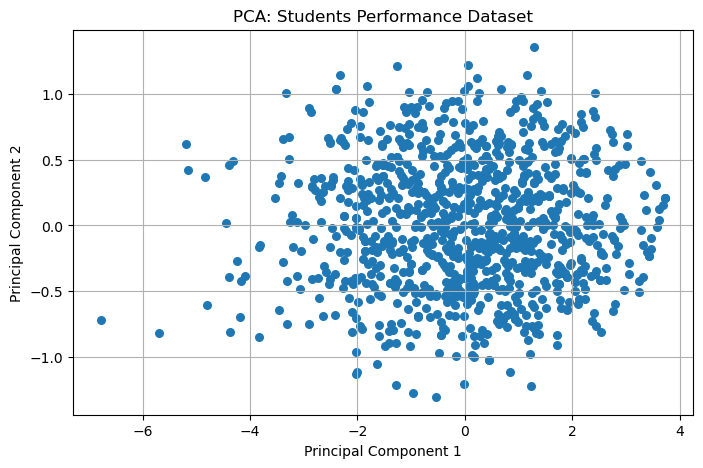

In [15]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a scatter plot using the two principal components
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Students Performance Dataset")
plt.grid(True)
plt.show()